<a href="https://colab.research.google.com/github/Abbbbabbbb/Projekt/blob/main/Projekt2D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install PyMPDATA

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyMPDATA]


In [2]:
! pip install pint

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pint]


In [3]:
import os
os.environ["NUMBA_THREADING_LAYER"]="workqueue"
os.environ["NUMBA_DISABLE_JIT"]="1"

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pint

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from PyMPDATA import Options, Stepper, Solver, ScalarField, VectorField
from PyMPDATA.boundary_conditions import Periodic

In [5]:
SI=pint.UnitRegistry()

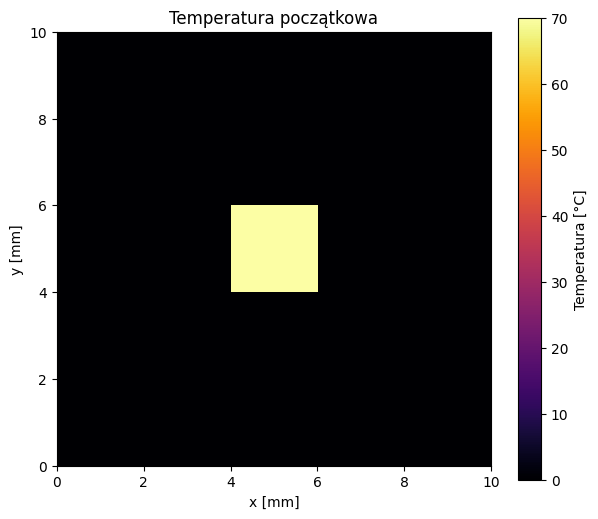

In [6]:
Lx=10.0
Ly=10.0
nx=100
ny=100
dx=Lx/nx
dy=Ly/ny
x=(np.arange(nx)+0.5)*dx
y=(np.arange(ny)+0.5)*dy
X,Y=np.meshgrid(x,y,indexing="ij")

T_0=70
T_init=np.full((nx,nx),0.0)
T_init[40:60, 40:60]=70.0

SI.setup_matplotlib()

plt.figure(figsize=(7, 6))
im=plt.imshow(T_init.T,
    origin="lower",
    extent=[0, Lx, 0, Ly],
    aspect="equal",
    cmap="inferno"
)
plt.gca().xaxis.set_units(SI.mm)
plt.gca().yaxis.set_units(SI.mm)
plt.gca().set_xlabel(f"x [{plt.gca().xaxis.units:~P}]")
plt.gca().set_ylabel(f"y [{plt.gca().xaxis.units:~P}]")
cbar=plt.colorbar(im)
cbar.set_label(f"Temperatura [{SI.celsius:~P}]")
plt.title("Temperatura początkowa")
plt.show()

In [7]:
u=0.3
v=0.3
dt=0.01
t_end=5.0
n_steps=int(t_end / dt)
alpha_x=0.15
alpha_y=0.1
mu_x=alpha_x*dt/dx**2
mu_y=alpha_y*dt/dy**2
Cx=u*dt/dx
Cy=v*dt/dy

print(mu_x)
print(mu_y)
print(mu_x+mu_y)
print(Cx)
print(Cy)

options=Options(n_iters=2, non_zero_mu_coeff=True)
stepper=Stepper(options=options,grid=(nx,ny))
halo=options.n_halo

advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
solver=Solver(stepper=stepper,advectee=advectee,advector=advector)

0.14999999999999997
0.09999999999999998
0.24999999999999994
0.03
0.03


In [8]:
snapshots=[solver.advectee.get().copy()]
times=[0.0]

for step in range(1,n_steps+1):

    solver.advance(n_steps=1,mu_coeff=(mu_x,mu_y))
    snapshots.append(solver.advectee.get().copy())
    times.append(step*dt)

snapshots=np.array(snapshots)
times=np.array(times)

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    snapshots[0].T,
    origin="lower",
    extent=[0, Lx, 0, Ly],
    aspect="equal",
    cmap="inferno",
    vmin=0,
    vmax=T_0,
    animated=True
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label(f"Temperatura [{SI.celsius:~P}]")

ax.xaxis.set_units(SI.mm)
ax.yaxis.set_units(SI.mm)
ax.set_xlabel(f"x [{ax.xaxis.units:~P}]")
ax.set_ylabel(f"y [{ax.yaxis.units:~P}]")
title = ax.set_title("2D advection: t = 0.00")

def update(frame):

    im.set_data(snapshots[frame].T)

    title.set_text(
        f"Czas: t = {times[frame]:.2f}"
    )

    return im, title

animation = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=30,
    blit=True
)

plt.close(fig)

HTML(animation.to_html5_video())

In [10]:
T_0=20.0
x0=3.0
y0=4.0
sigma=0.5

u=1
v=1

Lx=10.0
Ly=10.0
nx=100
ny=100
dx=Lx/nx
dy=Ly/ny
x=(np.arange(nx)+0.5)*dx
y=(np.arange(ny)+0.5)*dy
X,Y=np.meshgrid(x,y,indexing="ij")

t_end=3.0
dt_val=[0.024,0.02,0.015,0.01,0.001]
difference_t=[]
sol_t=[]

T_init=T_0*np.exp(-((X-x0)**2+(Y-y0)**2)/(2*sigma**2))
T_analitic=T_0*np.exp(-((X-x0-u*t_end)**2+(Y-y0-v*t_end)**2)/(2*sigma**2))


for dt in dt_val:

    n_steps=round(t_end/dt)


    Cx=u*dt/dx
    Cy=v*dt/dy

    options=Options(n_iters=1)
    stepper=Stepper(options=options,grid=(nx,ny))
    halo=options.n_halo

    advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    solver=Solver(stepper=stepper,advectee=advectee,advector=advector)

    for step in range(n_steps):
        solver.advance(n_steps=1)

    T_num=solver.advectee.get().copy()
    sol_t.append(T_num)
    diff_t=np.sqrt(np.mean((T_num-T_analitic)**2))

    difference_t.append(diff_t)

    print(f"dt = {dt:.4f}, RMSE = {diff_t:.6e}")



dt = 0.0240, RMSE = 6.841377e-01
dt = 0.0200, RMSE = 7.057473e-01
dt = 0.0150, RMSE = 7.316403e-01
dt = 0.0100, RMSE = 7.562424e-01
dt = 0.0010, RMSE = 7.973288e-01


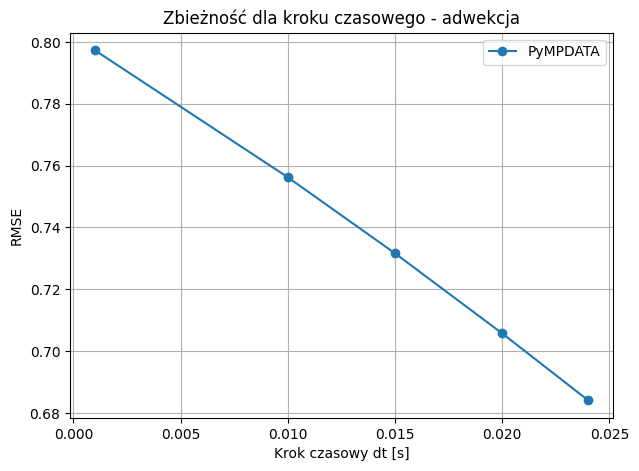

In [11]:
plt.figure(figsize=(7, 5))

plt.plot(
    dt_val,
    difference_t,
    "o-",
    label="PyMPDATA"
)

plt.xlabel("Krok czasowy dt [s]")
plt.ylabel("RMSE")
plt.title("Zbieżność dla kroku czasowego - adwekcja")

plt.grid(True, which="both")
plt.legend()


plt.show()

In [12]:
T_0=20.0
x0=3.0
y0=4.0
sigma=0.5

u=1
v=1

dt=0.01
t_end=3.0

difference_x=[]
sol_x=[]

Lx=10
Ly=10
nx_val=[50,80,100,200]

for nx in nx_val:

    ny=nx

    dx=Lx/nx
    dy=Ly/ny

    x=(np.arange(nx)+0.5)*dx
    y=(np.arange(ny)+0.5)*dy
    X,Y=np.meshgrid(x,y,indexing="ij")
    T_init=T_0*np.exp(-((X-x0)**2+(Y-y0)**2)/(2*sigma**2))
    T_analitic=T_0*np.exp(-((X-x0-u*t_end)**2+(Y-y0-v*t_end)**2)/(2*sigma**2))

    n_steps=round(t_end/dt)

    Cx=u*dt/dx
    Cy=v*dt/dx

    options=Options(n_iters=1)
    stepper=Stepper(options=options,grid=(nx,ny))
    halo=options.n_halo

    advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    solver=Solver(stepper=stepper,advectee=advectee,advector=advector)

    for step in range(n_steps):
        solver.advance(n_steps=1)

    T_num=solver.advectee.get().copy()
    sol_x.append(T_num)
    diff_x=np.sqrt(np.mean((T_num-T_analitic)**2))

    difference_x.append(diff_x)

    print(f"dx = {dx:.4f}, RMSE = {diff_x:.6e}")


Dx=[]
for i in range(0,4):
  Dx.append(Lx/nx_val[i])



dx = 0.2000, RMSE = 1.079722e+00
dx = 0.1250, RMSE = 8.625226e-01
dx = 0.1000, RMSE = 7.562424e-01
dx = 0.0500, RMSE = 4.454144e-01


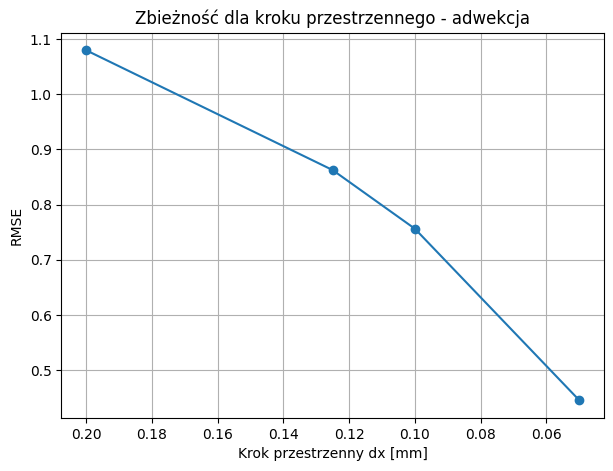

In [13]:
plt.figure(figsize=(7, 5))

plt.plot(
    Dx,
    difference_x,
    "o-"
)

plt.xlabel("Krok przestrzenny dx [mm]")
plt.ylabel("RMSE")
plt.title("Zbieżność dla kroku przestrzennego - adwekcja")
plt.gca().invert_xaxis()

plt.grid(True, which="both")

plt.show()

In [14]:
T_0=20.0
x0=3.0
y0=4.0
sigma=0.5

u=0.0
v=0.0

alpha_x=0.05
alpha_y=0.05

Lx=10.0
Ly=10.0
nx=100
ny=100
dx=Lx/nx
dy=Ly/ny
x=(np.arange(nx)+0.5)*dx
y=(np.arange(ny)+0.5)*dy
X,Y=np.meshgrid(x,y,indexing="ij")


t_end=1.0
dt_val=[0.024,0.02,0.015,0.01]
difference_tadv=[]
sol_tadv=[]


T_init=T_0*np.exp(-((X-x0)**2+(Y-y0)**2)/(2*sigma**2))
T_analitic=T_0*sigma**2/np.sqrt((sigma**2+2*alpha_x*t_end)*(sigma**2+2*alpha_y*t_end))*np.exp(-(X-x0)**2/(2*(sigma**2+2*alpha_x*t_end))-(Y-y0)**2/(2*(sigma**2+2*alpha_y*t_end)))


for dt in dt_val:

    n_steps=round(t_end/dt)

    Cx=u*dt/dx
    Cy=v*dt/dx

    mu_x=alpha_x*dt/dx**2
    mu_y=alpha_y*dt/dy**2

    options=Options(n_iters=2,non_zero_mu_coeff=True)
    stepper=Stepper(options=options,grid=(nx, ny))
    halo=options.n_halo

    advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    solver=Solver(stepper=stepper,advectee=advectee,advector=advector)

    for step in range(n_steps):
        solver.advance(n_steps=1,mu_coeff=(mu_x,mu_y))

    T_num=solver.advectee.get().copy()
    sol_tadv.append(T_num)
    diff_tadv=np.sqrt(np.mean((T_num-T_analitic)**2))

    difference_tadv.append(diff_tadv)

    print(f"dt = {dt:.4f}, RMSE = {diff_tadv:.6e}")

dt = 0.0240, RMSE = 7.221028e-03
dt = 0.0200, RMSE = 5.023113e-03
dt = 0.0150, RMSE = 5.751186e-03
dt = 0.0100, RMSE = 4.480415e-03


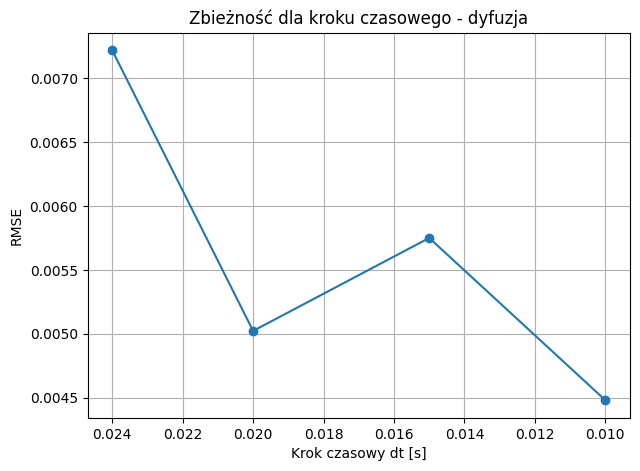

In [15]:
plt.figure(figsize=(7, 5))

plt.plot(
    dt_val,
    difference_tadv,
    "o-",
)

plt.xlabel("Krok czasowy dt [s]")
plt.ylabel("RMSE")
plt.title("Zbieżność dla kroku czasowego - dyfuzja")
plt.gca().invert_xaxis()

plt.grid(True, which="both")


plt.show()

In [16]:
T_0=20.0
x0=3.0
y0=4.0
sigma=0.5

u=0.0
v=0.0

dt=0.01
t_end=3.0

difference_xadv=[]
sol_xadv=[]

Lx=10
Ly=10
nx_val=[50,64,80,100]


for nx in nx_val:

    ny=nx

    dx=Lx/nx
    dy=Ly/ny

    x=(np.arange(nx)+0.5)*dx
    y=(np.arange(ny)+0.5)*dy
    X,Y=np.meshgrid(x,y,indexing="ij")
    T_init=T_0*np.exp(-((X-x0)**2+(Y-y0)**2)/(2*sigma**2))
    T_analitic=T_0*sigma**2/np.sqrt((sigma**2+2*alpha_x*t_end)*(sigma**2+2*alpha_y*t_end))*np.exp(-(X-x0)**2/(2*(sigma**2+2*alpha_x*t_end))-(Y-y0)**2/(2*(sigma**2+2*alpha_y*t_end)))

    n_steps=round(t_end/dt)

    Cx=u*dt/dx
    Cy=v*dt/dx

    options=Options(n_iters=2,non_zero_mu_coeff=True)
    stepper=Stepper(options=options,grid=(nx,ny))
    halo=options.n_halo

    advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    solver=Solver(stepper=stepper,advectee=advectee,advector=advector)

    for step in range(n_steps):
        solver.advance(n_steps=1,mu_coeff=(mu_x,mu_y))

    T_num=solver.advectee.get().copy()
    sol_xadv.append(T_num)
    diff_xadv=np.sqrt(np.mean((T_num-T_analitic)**2))

    difference_xadv.append(diff_xadv)

    print(f"dx = {dx:.4f}, RMSE = {diff_xadv:.6e}")

Dx_adv=[]
for i in range(0,4):
  Dx_adv.append(Lx/nx_val[i])



dx = 0.2000, RMSE = 6.397896e-01
dx = 0.1562, RMSE = 4.284869e-01
dx = 0.1250, RMSE = 2.169486e-01
dx = 0.1000, RMSE = 5.405632e-03


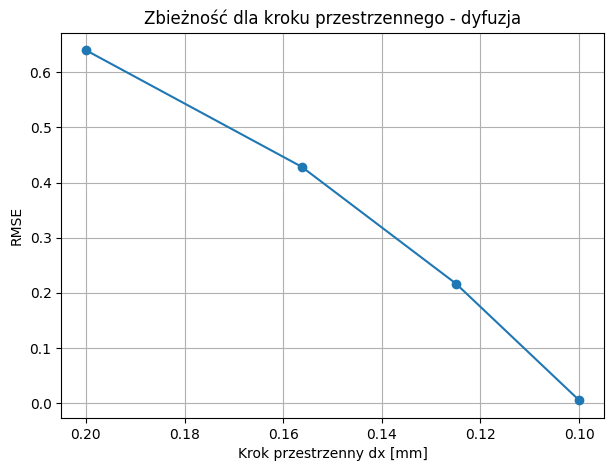

In [17]:
plt.figure(figsize=(7, 5))

plt.plot(
    Dx_adv,
    difference_xadv,
    "o-"
)

plt.xlabel("Krok przestrzenny dx [mm]")
plt.ylabel("RMSE")
plt.title("Zbieżność dla kroku przestrzennego - dyfuzja")
plt.gca().invert_xaxis()

plt.grid(True, which="both")

plt.show()

In [18]:
T_init=np.full((nx,nx),0.0)
T_init[40:60, 40:60]=70.0

Lx=10.0
Ly=10.0
nx=100
ny=100
dx=Lx/nx
dy=Ly/ny
x=(np.arange(nx)+0.5)*dx
y=(np.arange(ny)+0.5)*dy
X,Y=np.meshgrid(x,y,indexing="ij")
dt=0.009
t_end=3.0
n_steps=int(t_end/dt)

u=0.5
v=0.5

rho=1000
cw=4200
k_val=[0.01,0.1,0.5]
alpha_val=[]
mu_val=[]


Cx=u*dt/dx
Cy=v*dt/dy

for k in k_val:

    alpha=k/(rho*cw)*10**6
    mu_x=alpha*dt/dx**2
    mu_y=alpha*dt/dy**2

    alpha_val.append(alpha)
    mu_val.append((mu_x,mu_y))

print(alpha_val)
print(mu_val)

[0.002380952380952381, 0.02380952380952381, 0.11904761904761904]
[(0.0021428571428571425, 0.0021428571428571425), (0.021428571428571425, 0.021428571428571425), (0.10714285714285711, 0.10714285714285711)]


In [19]:
t_end=1.5
n_steps=round(t_end/dt)

frame_step=5
all_solutions=[]
frame_times=[]

for i in range(len(k_val)):

    mu_x,mu_y=mu_val[i]


    options=Options(n_iters=2,non_zero_mu_coeff=True)
    stepper=Stepper(options=options,grid=(nx,ny))
    halo=options.n_halo

    advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    solver=Solver(stepper=stepper,advectee=advectee,advector=advector)


    sol=[solver.advectee.get().copy()]

    for step in range(n_steps):

        solver.advance(n_steps=1,mu_coeff=(mu_x,mu_y))

        if (step+1) % frame_step == 0 or step == n_steps-1:
            sol.append(solver.advectee.get().copy())

    all_solutions.append(sol)

frame_times=[0.0]
for step in range(frame_step, n_steps+1, frame_step):
    frame_times.append(step*dt)

if frame_times[-1]<n_steps*dt:
    frame_times.append(n_steps*dt)

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = []

for i in range(3):

    im = axes[i].imshow(
        all_solutions[i][0].T,
        origin="lower",
        extent=[0, Lx, 0, Ly],
        cmap="inferno",
        vmin=0,
        vmax=np.max(T_init),
        animated=True
    )

    images.append(im)
    axes[i].set_title(f" Wspł. przew. cieplnego = {k_val[i]}")
    axes[i].set_xlabel(f"x [{SI.mm:~P}]")
    axes[i].set_ylabel(f"x [{SI.mm:~P}]")

fig.colorbar(
    images[0],
    ax=axes.ravel().tolist(),
    label=(f"Temperatura [{SI.celsius:~P}]")
)

def update(frame):

    for i in range(3):
        images[i].set_data(all_solutions[i][frame].T)

    fig.suptitle(
        f"Czas = {frame_times[frame]:.3f}"
    )

    return images

ani = FuncAnimation(
    fig,
    update,
    frames=len(all_solutions[0]),
    interval=80,
    blit=False
)

plt.close()

HTML(ani.to_jshtml())

In [21]:
T_init=np.full((nx,nx),0.0)
T_init[40:60, 40:60]=70.0

Lx=10.0
Ly=10.0
nx=100
ny=100
dx=Lx/nx
dy=Ly/ny
x=(np.arange(nx)+0.5)*dx
y=(np.arange(ny)+0.5)*dy
X,Y=np.meshgrid(x,y,indexing="ij")
dt=0.009
t_end=3.0
n_steps=int(t_end/dt)

u_val=[0.001, 0.01, 1]
v_val=u_val.copy()
alpha=0.1
Pe_val=[]

for u in u_val:
    Pe_val.append(Lx*u/alpha)


In [22]:
t_end=1.5
n_steps=round(t_end/dt)

frame_step=5
all_solutions=[]
frame_times=[]

for u in range(len(u_val)):

    mu_x=alpha*dt/dx**2
    mu_y=alpha*dt/dx**2

    Cx=u*dt/dx
    Cy=u*dt/dy

    options=Options(n_iters=2,non_zero_mu_coeff=True)
    stepper=Stepper(options=options,grid=(nx,ny))
    halo=options.n_halo

    advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
    solver=Solver(stepper=stepper,advectee=advectee,advector=advector)


    sol=[solver.advectee.get().copy()]

    for step in range(n_steps):

        solver.advance(n_steps=1,mu_coeff=(mu_x,mu_y))

        if (step+1) % frame_step == 0 or step == n_steps-1:
            sol.append(solver.advectee.get().copy())

    all_solutions.append(sol)

frame_times=[0.0]
for step in range(frame_step, n_steps+1, frame_step):
    frame_times.append(step*dt)

if frame_times[-1]<n_steps*dt:
    frame_times.append(n_steps*dt)



In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = []

for i in range(3):

    im = axes[i].imshow(
        all_solutions[i][0].T,
        origin="lower",
        extent=[0, Lx, 0, Ly],
        cmap="inferno",
        vmin=0,
        vmax=np.max(T_init),
        animated=True
    )



    images.append(im)
    axes[i].set_title(f"Liczba Pecleta = {Pe_val[i]}")
    axes[i].set_xlabel(f"x [{SI.mm:~P}]")
    axes[i].set_ylabel(f"x [{SI.mm:~P}]")

fig.colorbar(
    images[0],
    ax=axes.ravel().tolist(),
    label=(f"Temperatura [{SI.celsius:~P}]")
)

def update(frame):

    for i in range(3):
        images[i].set_data(all_solutions[i][frame].T)

    fig.suptitle(
        f"Czas = {frame_times[frame]:.3f}"
    )

    return images

ani = FuncAnimation(
    fig,
    update,
    frames=len(all_solutions[0]),
    interval=80,
    blit=False
)

plt.close()

HTML(ani.to_jshtml())

In [24]:
T_init=np.full((nx,nx),0.0)
T_init[40:60, 40:60]=70.0

Lx=10.0
Ly=10.0
nx=100
ny=100
dx=Lx/nx
dy=Ly/ny
x=(np.arange(nx)+0.5)*dx
y=(np.arange(ny)+0.5)*dy
X,Y=np.meshgrid(x,y,indexing="ij")
dt=0.009
t_end=3.0
n_steps=int(t_end/dt)

u=0.7
v=0.0

rho1=950
k1=0.18
cw1=1600

rho2=1000
k2=0.6
cw2=4200

Cx=u*dt/dx
Cy=v*dt/dx

alpha1=k1/(rho1*cw1)*10**6
alpha2=k2/(rho2*cw2)*10**6
mu1=alpha1*dt/dx**2
mu2=alpha2*dt/dy**2


print(Cx)
print(Cy)
print(mu1)
print(mu2)



0.06299999999999999
0.0
0.10657894736842102
0.12857142857142853


In [25]:
options=Options(n_iters=2, non_zero_mu_coeff=True)
stepper=Stepper(options=options,grid=(nx, ny))
halo=options.n_halo

advectee=ScalarField(data=T_init.copy(),halo=halo,boundary_conditions=(Periodic(),Periodic()))
advector=VectorField(data=(np.full((nx+1,ny),Cx),np.full((nx,ny+1),Cy)),halo=halo,boundary_conditions=(Periodic(),Periodic()))
solver=Solver(stepper=stepper,advectee=advectee,advector=advector)

snapshots=[solver.advectee.get().copy()]
times=[0.0]

for step in range(1, n_steps + 1):

    solver.advance(n_steps=1,mu_coeff=(mu1, mu2))
    snapshots.append(solver.advectee.get().copy())
    times.append(step*dt)

snapshots=np.array(snapshots)
times=np.array(times)

In [27]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    snapshots[0].T,
    origin="lower",
    extent=[0, Lx, 0, Ly],
    aspect="equal",
    cmap="inferno",
    vmin=0,
    vmax=T_0,
    animated=True
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label(f"Temperatura [{SI.celsius:~P}]")

ax.xaxis.set_units(SI.centimeter)
ax.yaxis.set_units(SI.centimeter)
ax.set_xlabel(f"x [{ax.xaxis.units:~P}]")
ax.set_ylabel(f"y [{ax.yaxis.units:~P}]")
title = ax.set_title("2D advection: t = 0.00")

def update(frame):

    im.set_data(snapshots[frame].T)

    title.set_text(
        f"Czas: t = {times[frame]:.2f}"
    )

    return im, title

animation = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=30,
    blit=True
)

plt.close(fig)

HTML(animation.to_html5_video())